<a href="https://colab.research.google.com/github/radhey8171/Python_Project/blob/main/Assignment_4_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Loaded Successfully
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset Shape: (200, 5)

Missing Values:
 CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


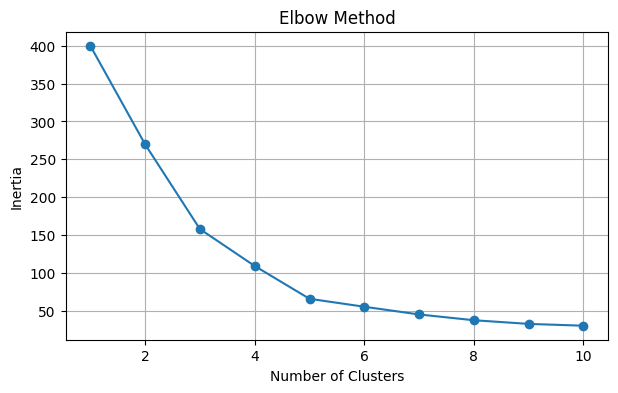


Silhouette Score: 0.555


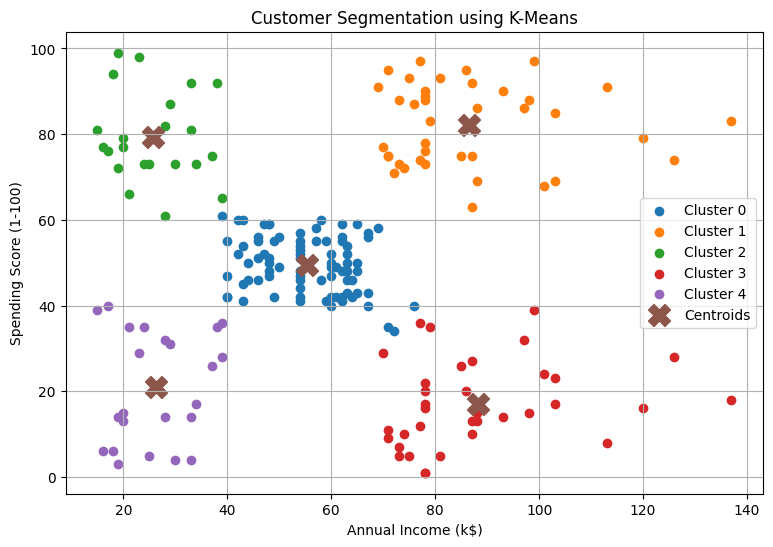


Cluster Analysis:

           Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0        42.72               55.30                   49.52
1        32.69               86.54                   82.13
2        25.27               25.73                   79.36
3        41.11               88.20                   17.11
4        45.22               26.30                   20.91

Customer Group Counts:
Customer Group
Medium Spenders                   78
Low Spenders                      59
High Value Customers              38
Young/Low Income High Spenders    25
Name: count, dtype: int64

Project Completed Successfully!
Results saved to Customer_Segmentation_Results.csv
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16  

In [1]:

# MAJOR PROJECT: CUSTOMER SEGMENTATION USING CLUSTERING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 1. Load Dataset
url = "https://raw.githubusercontent.com/anujvyas/Machine-Learning-Projects/master/Mall%20Customer%20Segmentation/Mall%20Customer%20Segmentation%20-%20PPT.pdf"

# Load the CSV dataset directly
csv_url = "https://raw.githubusercontent.com/SteffiPeTaffy/machineLearningAZ/master/Machine%20Learning%20A-Z%20Template%20Folder/Part%204%20-%20Clustering/Section%2025%20-%20Hierarchical%20Clustering/Mall_Customers.csv"

df = pd.read_csv(csv_url)

print("Dataset Loaded Successfully")
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())

# 2. Data Cleaning
df.columns = df.columns.str.strip()
df = df.drop_duplicates()

# Select important features
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()
X = X.fillna(X.median())

# 3. Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Find Optimal Clusters using Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

# 5. Train K-Means Model
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# 6. Evaluate Clustering
score = silhouette_score(X_scaled, df["Cluster"])
print("\nSilhouette Score:", round(score, 3))

# 7. Visualize Customer Groups
plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster]
    plt.scatter(
        group["Annual Income (k$)"],
        group["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

centers = scaler.inverse_transform(kmeans.cluster_centers_)

plt.scatter(
    centers[:, 0], centers[:, 1],
    marker="X", s=250, label="Centroids"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True)
plt.show()

# 8. Analyze Each Cluster
summary = df.groupby("Cluster")[
    ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
].mean().round(2)

print("\nCluster Analysis:\n")
print(summary)

# 9. Assign Customer Group Names
def label_cluster(row):
    income = row["Annual Income (k$)"]
    spending = row["Spending Score (1-100)"]

    if income >= 70 and spending >= 60:
        return "High Value Customers"
    elif income < 50 and spending >= 60:
        return "Young/Low Income High Spenders"
    elif spending < 40:
        return "Low Spenders"
    else:
        return "Medium Spenders"

df["Customer Group"] = df.apply(label_cluster, axis=1)

print("\nCustomer Group Counts:")
print(df["Customer Group"].value_counts())

# 10. Save Final Results
df.to_csv("Customer_Segmentation_Results.csv", index=False)

print("\nProject Completed Successfully!")
print("Results saved to Customer_Segmentation_Results.csv")

# 11. Show Final Data
print(df.head(10))
